# 03: De Chaisemartin & D'Haultfœuille (2024) 推定

TWFEのsign flip問題に対する診断として、dcDH (2024) の連続処置DiD推定量を実装・適用する。

## 推定量の概要

dcDH (2024) は2期間・連続処置の設定で、stayerが存在しなくても適用可能な推定量を提案。

**キーアイデア**: ΔD→0の極限で、処置変化の因果効果と潜在的トレンドを分離する。

**パラメトリック推定量**:
1. $E[\Delta Y | D_1, \Delta D] = g_\lambda(D_1, \Delta D)$ をパラメトリックに推定
2. $\hat{\theta} = \frac{\sum_i S_i(\Delta Y_i - g_{\hat\lambda}(D_{1i}, 0))}{\sum_i |\Delta D_i|}$

ここで $S_i = \text{sign}(\Delta D_i)$、$g_{\hat\lambda}(D_1, 0)$ は処置変化がなかった場合の反事実的トレンド。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
import japanize_matplotlib

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)

## データ準備

In [2]:
annual = pd.read_csv('../data/annual_panel.csv')

# 不完全年を除外: 2012(9m), 2018(3m), 2019(9m), 2025(6m)
clean_years = [2013, 2014, 2015, 2016, 2017, 2020, 2021, 2022, 2023, 2024]
df = annual[annual.mw_year.isin(clean_years)].copy()
print(f'Clean years: {sorted(df.mw_year.unique())}')
print(f'Shape: {df.shape}')

Clean years: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Shape: (470, 19)


In [3]:
# dcDH用の first-difference データを構築
# D1 = 前年のlog(MW), delta_D = dlog_mw, delta_Y = Y_t - Y_{t-1}

outcomes = ['log_wage_scheduled', 'log_hours_total', 'hours_overtime']
outcome_labels = {'log_wage_scheduled': 'log(所定内給与)', 
                  'log_hours_total': 'log(総実労働時間)',
                  'hours_overtime': '所定外労働時間'}

df = df.sort_values(['pref_code', 'mw_year'])

# First-difference outcomes
for col in outcomes:
    df[f'd_{col}'] = df.groupby('pref_code')[col].diff()

# D1 = lagged log_mw
df['D1'] = df.groupby('pref_code')['log_mw'].shift(1)

# Drop rows without valid first-differences
# Need consecutive clean years: can't diff across 2017→2020 gap
df['prev_year'] = df.groupby('pref_code')['mw_year'].shift(1)
df['consecutive'] = (df['mw_year'] - df['prev_year']) == 1

fd = df[df['consecutive'] & df['dlog_mw'].notna() & df['D1'].notna()].copy()
print(f'First-difference obs: {len(fd)}')
print(f'Years with valid FD: {sorted(fd.mw_year.unique())}')
print(f'\ndlog_mw == 0: {(fd.dlog_mw == 0).sum()} obs (will exclude from dcDH)')

First-difference obs: 376
Years with valid FD: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

dlog_mw == 0: 1 obs (will exclude from dcDH)


In [4]:
# Exclude dlog_mw == 0 (dcDH divides by |delta_D|)
fd_pos = fd[fd.dlog_mw > 0].copy()
print(f'Estimation sample: {len(fd_pos)} obs')
print(f'Dropped {len(fd) - len(fd_pos)} zero-dose obs')

Estimation sample: 375 obs
Dropped 1 zero-dose obs


## dcDH推定量の実装

In [5]:
def dcdh_estimate(D1, delta_D, delta_Y, spec='linear'):
    """
    De Chaisemartin & D'Haultfœuille (2024) parametric estimator.
    
    Parameters
    ----------
    D1 : array - initial treatment level
    delta_D : array - treatment change (must be nonzero)
    delta_Y : array - outcome change
    spec : str - 'linear' or 'quadratic' for g(D1, delta_D)
    
    Returns
    -------
    dict with theta, se, ci_lower, ci_upper, n, first_stage
    """
    n = len(D1)
    S = np.sign(delta_D)
    abs_dD = np.abs(delta_D)
    
    # Step 1: parametric model for E[delta_Y | D1, delta_D]
    if spec == 'linear':
        # g(D1, dD) = lam1 + lam2*D1 + lam3*dD + lam4*D1*dD
        X = np.column_stack([
            np.ones(n), D1, delta_D, D1 * delta_D
        ])
    elif spec == 'quadratic':
        # g(D1, dD) = lam1 + lam2*D1 + lam3*dD + lam4*D1*dD + lam5*dD^2
        X = np.column_stack([
            np.ones(n), D1, delta_D, D1 * delta_D, delta_D**2
        ])
    
    ols = sm.OLS(delta_Y, X).fit()
    lam_hat = ols.params
    
    # Step 2: counterfactual trend g(D1, 0)
    if spec == 'linear':
        X0 = np.column_stack([np.ones(n), D1, np.zeros(n), np.zeros(n)])
    elif spec == 'quadratic':
        X0 = np.column_stack([np.ones(n), D1, np.zeros(n), np.zeros(n), np.zeros(n)])
    
    g_hat_0 = X0 @ lam_hat  # predicted trend at delta_D = 0
    
    # theta = sum S_i * (dY_i - g(D1_i, 0)) / sum |dD_i|
    numerator = np.sum(S * (delta_Y - g_hat_0))
    denominator = np.sum(abs_dD)
    theta = numerator / denominator
    
    # Standard error via influence function
    # Simplified: bootstrap SE
    np.random.seed(42)
    n_boot = 500
    theta_boot = np.zeros(n_boot)
    
    # Cluster bootstrap by prefecture (if we have pref info)
    # For now, pairs bootstrap
    for b in range(n_boot):
        idx = np.random.choice(n, size=n, replace=True)
        D1_b, dD_b, dY_b = D1[idx], delta_D[idx], delta_Y[idx]
        S_b = np.sign(dD_b)
        
        if spec == 'linear':
            X_b = np.column_stack([np.ones(n), D1_b, dD_b, D1_b * dD_b])
            X0_b = np.column_stack([np.ones(n), D1_b, np.zeros(n), np.zeros(n)])
        elif spec == 'quadratic':
            X_b = np.column_stack([np.ones(n), D1_b, dD_b, D1_b * dD_b, dD_b**2])
            X0_b = np.column_stack([np.ones(n), D1_b, np.zeros(n), np.zeros(n), np.zeros(n)])
        
        try:
            ols_b = sm.OLS(dY_b, X_b).fit()
            g0_b = X0_b @ ols_b.params
            theta_boot[b] = np.sum(S_b * (dY_b - g0_b)) / np.sum(np.abs(dD_b))
        except:
            theta_boot[b] = np.nan
    
    se = np.nanstd(theta_boot)
    
    return {
        'theta': theta,
        'se': se,
        'ci_lower': theta - 1.96 * se,
        'ci_upper': theta + 1.96 * se,
        'p': 2 * (1 - stats.norm.cdf(abs(theta / se))) if se > 0 else np.nan,
        'n': n,
        'first_stage': ols.summary2().tables[1]
    }

## フルサンプル推定

In [6]:
results_full = {}
for yvar in outcomes:
    dy = fd_pos[f'd_{yvar}'].values
    D1_arr = fd_pos['D1'].values
    dD_arr = fd_pos['dlog_mw'].values
    
    res = dcdh_estimate(D1_arr, dD_arr, dy, spec='linear')
    results_full[yvar] = res
    
    label = outcome_labels[yvar]
    sig = '***' if res['p'] < 0.01 else '**' if res['p'] < 0.05 else '*' if res['p'] < 0.1 else ''
    print(f'{label}: θ = {res["theta"]:.4f} (SE = {res["se"]:.4f}){sig}  N={res["n"]}')

print('\n--- dcDH推定量の解釈 ---')
print('θ = Δlog(MW) 1単位あたりのアウトカム変化の平均効果')
print('log-logの場合は弾力性に近い解釈')

log(所定内給与): θ = 0.4903 (SE = 0.1064)***  N=375


log(総実労働時間): θ = -0.0642 (SE = 0.0763)  N=375


所定外労働時間: θ = -4.1842 (SE = 3.7456)  N=375

--- dcDH推定量の解釈 ---
θ = Δlog(MW) 1単位あたりのアウトカム変化の平均効果
log-logの場合は弾力性に近い解釈


## 期間別推定（sign flip診断）

TWFEのsign flipがdcDHでも再現するかが核心的問い。

In [7]:
# Early: 2014-2017, Late: 2021-2024
early = fd_pos[fd_pos.mw_year.isin([2014, 2015, 2016, 2017])]
late = fd_pos[fd_pos.mw_year.isin([2021, 2022, 2023, 2024])]

print(f'Early sample: {len(early)} obs (mw_years {sorted(early.mw_year.unique())})')
print(f'Late sample:  {len(late)} obs (mw_years {sorted(late.mw_year.unique())})')

results_by_period = {}
for period_name, subset in [('2014-2017', early), ('2021-2024', late)]:
    print(f'\n=== {period_name} ===')
    results_by_period[period_name] = {}
    for yvar in outcomes:
        dy = subset[f'd_{yvar}'].values
        D1_arr = subset['D1'].values
        dD_arr = subset['dlog_mw'].values
        
        res = dcdh_estimate(D1_arr, dD_arr, dy, spec='linear')
        results_by_period[period_name][yvar] = res
        
        label = outcome_labels[yvar]
        sig = '***' if res['p'] < 0.01 else '**' if res['p'] < 0.05 else '*' if res['p'] < 0.1 else ''
        print(f'  {label}: θ = {res["theta"]:.4f} (SE = {res["se"]:.4f}){sig}')

Early sample: 187 obs (mw_years [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)])
Late sample:  188 obs (mw_years [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)])

=== 2014-2017 ===


  log(所定内給与): θ = -0.4939 (SE = 0.2528)*


  log(総実労働時間): θ = -0.1319 (SE = 0.1712)


  所定外労働時間: θ = 10.4560 (SE = 9.0729)

=== 2021-2024 ===


  log(所定内給与): θ = 0.8716 (SE = 0.1178)***


  log(総実労働時間): θ = -0.0947 (SE = 0.1003)


  所定外労働時間: θ = -15.7512 (SE = 4.8328)***


In [8]:
# Sign flip comparison table: TWFE vs dcDH
print('='*80)
print('TWFE vs dcDH: Sign Flip 診断')
print('='*80)

twfe_signs = {
    'log_wage_scheduled': {'early': -0.7301, 'late': 0.0914},
    'log_hours_total': {'early': 0.2214, 'late': -0.1932},
    'hours_overtime': {'early': 17.58, 'late': -7.06},
}

print(f'{"":<25} {"TWFE Early":>12} {"TWFE Late":>12} {"TWFE flip":>10} │ {"dcDH Early":>12} {"dcDH Late":>12} {"dcDH flip":>10}')
print('-'*105)

for yvar in outcomes:
    label = outcome_labels[yvar]
    te = twfe_signs[yvar]['early']
    tl = twfe_signs[yvar]['late']
    t_flip = 'YES' if np.sign(te) != np.sign(tl) else 'no'
    
    de = results_by_period['2014-2017'][yvar]['theta']
    dl = results_by_period['2021-2024'][yvar]['theta']
    d_flip = 'YES' if np.sign(de) != np.sign(dl) else 'no'
    
    print(f'{label:<25} {te:>12.4f} {tl:>12.4f} {t_flip:>10} │ {de:>12.4f} {dl:>12.4f} {d_flip:>10}')

TWFE vs dcDH: Sign Flip 診断
                            TWFE Early    TWFE Late  TWFE flip │   dcDH Early    dcDH Late  dcDH flip
---------------------------------------------------------------------------------------------------------
log(所定内給与)                     -0.7301       0.0914        YES │      -0.4939       0.8716        YES
log(総実労働時間)                     0.2214      -0.1932        YES │      -0.1319      -0.0947         no
所定外労働時間                        17.5800      -7.0600        YES │      10.4560     -15.7512        YES


## 年次別推定（安定性チェック）

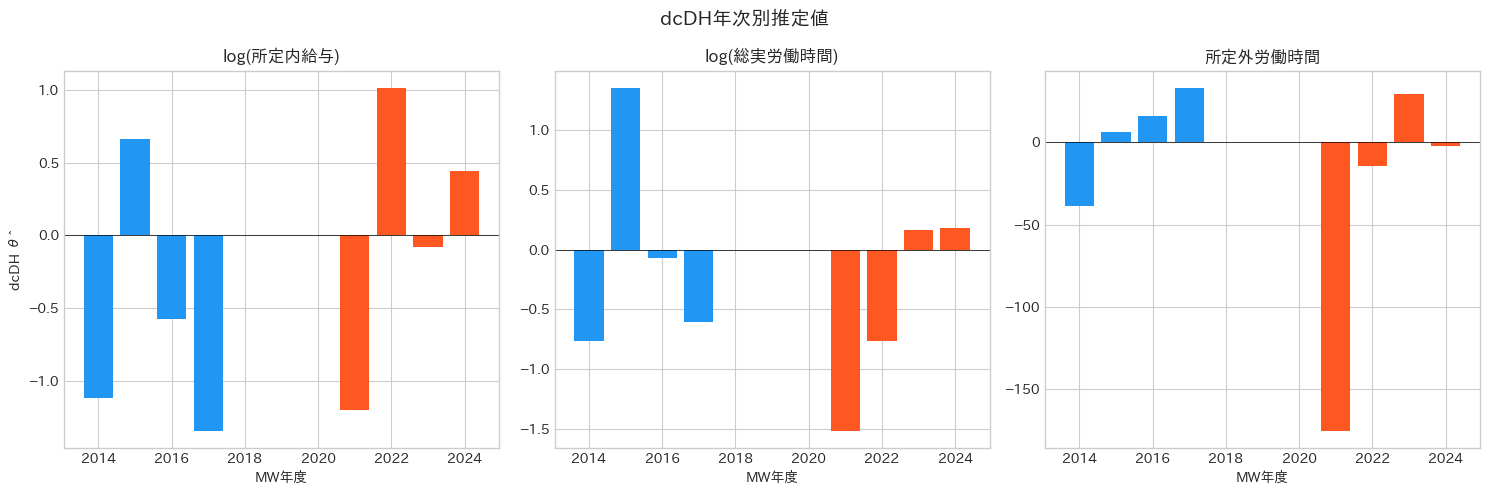

In [9]:
# Year-by-year dcDH estimates
yearly_results = []
for yr in sorted(fd_pos.mw_year.unique()):
    subset = fd_pos[fd_pos.mw_year == yr]
    if len(subset) < 10:
        continue
    for yvar in outcomes:
        dy = subset[f'd_{yvar}'].values
        D1_arr = subset['D1'].values
        dD_arr = subset['dlog_mw'].values
        
        # Simpler spec for year-by-year (fewer obs)
        # Just linear: g(D1, dD) = a + b*D1 + c*dD
        n = len(D1_arr)
        X = np.column_stack([np.ones(n), D1_arr, dD_arr])
        X0 = np.column_stack([np.ones(n), D1_arr, np.zeros(n)])
        
        try:
            ols = sm.OLS(dy, X).fit()
            g0 = X0 @ ols.params
            S = np.sign(dD_arr)
            theta = np.sum(S * (dy - g0)) / np.sum(np.abs(dD_arr))
            yearly_results.append({'mw_year': yr, 'outcome': yvar, 'theta': theta, 'n': n})
        except:
            pass

yr_df = pd.DataFrame(yearly_results)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, yvar in enumerate(outcomes):
    sub = yr_df[yr_df.outcome == yvar]
    ax = axes[i]
    ax.bar(sub.mw_year, sub.theta, color=['#2196F3' if y <= 2017 else '#FF5722' for y in sub.mw_year])
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_title(outcome_labels[yvar])
    ax.set_xlabel('MW年度')
    if i == 0:
        ax.set_ylabel('dcDH θ̂')

fig.suptitle('dcDH年次別推定値', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../output/figures/03_dcdh_yearly.png', dpi=150, bbox_inches='tight')
plt.show()

## Robustness: Quadratic specification

In [10]:
print('=== Quadratic specification ===')
for period_name, subset in [('Full', fd_pos), ('2014-2017', early), ('2021-2024', late)]:
    print(f'\n--- {period_name} ---')
    for yvar in outcomes:
        dy = subset[f'd_{yvar}'].values
        D1_arr = subset['D1'].values
        dD_arr = subset['dlog_mw'].values
        
        res = dcdh_estimate(D1_arr, dD_arr, dy, spec='quadratic')
        label = outcome_labels[yvar]
        sig = '***' if res['p'] < 0.01 else '**' if res['p'] < 0.05 else '*' if res['p'] < 0.1 else ''
        print(f'  {label}: θ = {res["theta"]:.4f} (SE = {res["se"]:.4f}){sig}')

=== Quadratic specification ===

--- Full ---
  log(所定内給与): θ = 0.4623 (SE = 0.2429)*


  log(総実労働時間): θ = -0.3417 (SE = 0.1900)*
  所定外労働時間: θ = -4.1280 (SE = 11.4780)

--- 2014-2017 ---


  log(所定内給与): θ = 0.2412 (SE = 1.3195)
  log(総実労働時間): θ = -0.8054 (SE = 1.0883)


  所定外労働時間: θ = 6.8833 (SE = 77.2877)

--- 2021-2024 ---
  log(所定内給与): θ = 1.3553 (SE = 0.6748)**


  log(総実労働時間): θ = -0.6927 (SE = 0.3727)*
  所定外労働時間: θ = -58.7917 (SE = 27.1294)**


## 結果の保存

In [11]:
# Save results
rows = []
for period_name in ['Full', '2014-2017', '2021-2024']:
    if period_name == 'Full':
        src = results_full
    else:
        src = results_by_period[period_name]
    for yvar in outcomes:
        r = src[yvar]
        rows.append({
            'sample': period_name,
            'outcome': outcome_labels[yvar],
            'theta': r['theta'],
            'se': r['se'],
            'p': r['p'],
            'ci_lower': r['ci_lower'],
            'ci_upper': r['ci_upper'],
            'N': r['n'],
        })

res_df = pd.DataFrame(rows)
res_df.to_csv('../output/dcdh_results.csv', index=False)
print(res_df.to_string(index=False))

   sample     outcome      theta       se            p   ci_lower  ci_upper   N
     Full  log(所定内給与)   0.490337 0.106357 4.021244e-06   0.281877  0.698798 375
     Full log(総実労働時間)  -0.064193 0.076339 4.004117e-01  -0.213818  0.085432 375
     Full     所定外労働時間  -4.184186 3.745589 2.639528e-01 -11.525540  3.157168 375
2014-2017  log(所定内給与)  -0.493895 0.252797 5.073426e-02  -0.989376  0.001587 187
2014-2017 log(総実労働時間)  -0.131875 0.171173 4.410501e-01  -0.467374  0.203623 187
2014-2017     所定外労働時間  10.455995 9.072940 2.491414e-01  -7.326966 28.238957 187
2021-2024  log(所定内給与)   0.871629 0.117773 1.352252e-13   0.640794  1.102464 188
2021-2024 log(総実労働時間)  -0.094694 0.100335 3.452823e-01  -0.291351  0.101963 188
2021-2024     所定外労働時間 -15.751217 4.832790 1.117115e-03 -25.223484 -6.278949 188
